# 02 · Traditional machine learning benchmarks
## Temporal Graph Neural Networks for Risk Detection Under Distribution Shift

**Question:** How well do Logistic Regression and LightGBM rank known-label illicit transactions in later validation periods, under matched feature configurations?

This notebook fits conventional models on steps **1–29** and never predicts or ranks final-test steps **35–49**. Its main interface is the editable configuration and explicit training loops below. No tuning framework is required.

The **165-feature LightGBM is not a graph-free information baseline**: published columns 95–166 already contain engineered neighborhood information. Likewise, many nominally local columns contain address histories. The 18-, 93- and 165-feature configurations are benchmark/sensitivity settings; **none is certified leakage-free**. See the Stage 1 audit.

This is a validation study, not the final research result. Stage 1 disclosed test class summaries; Stage 2 adds no predictive test exposure. The original loader still reads and validates the release's files/counts, but only development rows enter the code that fits or predicts models.

## 1. Configuration and reproducibility

FULL_RUN uses two candidates per model family, two weighting regimes and four feature configurations. QUICK_RUN retains the full supervised population but reduces candidates/tree counts; its outputs are explicitly exploratory and stored separately. One configurable seed is adequate for these deterministic CPU baselines; the later neural comparison will require multiple seeds. No seed is selected for its score.

In [1]:
from pathlib import Path
import os
import sys
import time
import json
import hashlib
import warnings
import platform
import importlib.metadata

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").is_file():
    raise RuntimeError("Launch Jupyter from the repository root or notebooks/.")
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))

RUN_MODE = "FULL_RUN"  # QUICK_RUN is exploratory, never final research evidence.
if RUN_MODE not in {"QUICK_RUN", "FULL_RUN"}:
    raise ValueError("Choose QUICK_RUN or FULL_RUN")
QUICK_RUN = RUN_MODE == "QUICK_RUN"
SEEDS = [42]  # Configurable; keep the same seeds for every configuration.
PRIMARY_SEED = SEEDS[0]
N_JOBS = 2
TARGET_FPR = 0.01
REVIEW_K = 25  # Up to 25 labeled candidates per snapshot.
REVIEW_FRACTIONS = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]
MODE_FOLDER = "quick_run" if QUICK_RUN else "full_run"
DATA_DIR = Path(os.environ.get("ELLIPTIC_DATA_DIR", "data/raw"))
if not DATA_DIR.is_absolute():
    DATA_DIR = ROOT / DATA_DIR
RESULT_DIR = ROOT / "results" / "stage2" / MODE_FOLDER
PRIVATE_DIR = ROOT / "results" / "local" / "stage2" / MODE_FOLDER
MODEL_DIR = ROOT / "models" / "stage2" / MODE_FOLDER
FIGURE_DIR = ROOT / "reports" / "figures"
if QUICK_RUN:
    FIGURE_DIR = FIGURE_DIR / "exploratory_stage2"
for directory in [RESULT_DIR, PRIVATE_DIR, MODEL_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
started_at = time.perf_counter()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

from src.data import load_elliptic, file_fingerprints
from src.protocol import chronological_partitions
from src.baselines import (VALIDATION_ROLES, baseline_feature_sets, development_frames,
                           make_baseline, fit_sigmoid_calibrator, apply_sigmoid, decision_scores)
from src.evaluation import (PREDICTION_COLUMNS, binary_metrics, prediction_frame, choose_thresholds,
                           assert_common_population, review_budget_metrics, evaluate_predictions)

FEATURE_SETS = baseline_feature_sets()
PARAMETER_GRID = {
    "logistic_regression": [{"C": 0.1}, {"C": 1.0}],
    "lightgbm": [{"n_estimators": 200, "num_leaves": 15},
                 {"n_estimators": 350, "num_leaves": 31}],
}
if QUICK_RUN:
    PARAMETER_GRID = {"logistic_regression": [{"C": 1.0}],
                      "lightgbm": [{"n_estimators": 80, "num_leaves": 15}]}
WEIGHTING_REGIMES = ["ordinary", "balanced"]
FAMILY_NAMES = {"logistic_regression": "Logistic Regression", "lightgbm": "LightGBM"}
GROUP_NAMES = {"conservative18": "Transaction 18", "local93": "Local 93",
               "published165": "Published 165", "published165_plus_time": "Published 165 + time"}
COLORS = {"logistic_regression": "#0072B2", "lightgbm": "#D55E00"}
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "svg.fonttype": "none",
                     "axes.spines.top": False, "axes.spines.right": False})
figure_names = []

def save_figure(figure, name):
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    figure_names.append(name)
    plt.show()
    plt.close(figure)

print(f"{RUN_MODE}; exploratory={QUICK_RUN}; seeds={SEEDS}; CPU threads={N_JOBS}")
print("No final-test predictions or model rankings are permitted in this notebook.")

FULL_RUN; exploratory=False; seeds=[42]; CPU threads=2
No final-test predictions or model rankings are permitted in this notebook.


## 2. Data integrity and chronological validation roles

The base classifiers fit only **known labels from steps 1–29**. To separate later choices chronologically:

| Role | Steps | Permitted use |
|---|---|---|
| Hyperparameter selection | 30–31 | AP selects candidates and weighting within each family/configuration |
| Calibration and operating rules | 32–33 | Fit the fixed Platt-style transform and choose F1/FPR thresholds |
| Later validation assessment | 34 | Compare the frozen development choices; no retuning in this notebook |
| Final test | 35–49 | No model prediction, calibration or ranking in Stage 2 |

Calibration and thresholds share their window; their fit-window performance is not independent evaluation. Step 34 is an independent later validation snapshot for Stage 2, not a replacement for the final test. It is small, dependent, and can be reused for validation in later stages, so no final generalization claim follows.

In [2]:
nodes, released_edges, diagnostics = load_elliptic(DATA_DIR)
raw_hashes = file_fingerprints(DATA_DIR)
manifest_path = ROOT / "data" / "processed" / "split_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError("Run the Stage 1 notebook to create local chronological memberships first.")
manifest = json.loads(manifest_path.read_text())
if manifest["raw_sha256"] != raw_hashes:
    raise ValueError("Input hashes differ from the Stage 1 split manifest")

# Check Stage 1 memberships without exporting IDs or test rows.
development_nodes = nodes.loc[nodes.time_step <= 34].copy()
membership = pd.read_csv(ROOT / "data" / "processed" / "split_membership.csv", dtype={"tx_id": str})
stored_development = membership.loc[membership.time_step <= 34].set_index("tx_id")
observed_development = development_nodes.set_index("tx_id")
assert set(stored_development.index) == set(observed_development.index)
assert (stored_development.loc[observed_development.index, "partition"].to_numpy()
        == chronological_partitions(development_nodes).to_numpy()).all()
assert (stored_development.loc[observed_development.index, "time_step"].to_numpy()
        == development_nodes.time_step.to_numpy()).all()
assert (stored_development.loc[observed_development.index, "node_index"].to_numpy()
        == development_nodes.node_index.to_numpy()).all()
frames = development_frames(development_nodes)
train_rows, selection_rows = frames["train"], frames["selection"]
calibration_rows, audit_rows = frames["calibration"], frames["audit"]
validation_rows = pd.concat([selection_rows, calibration_rows, audit_rows]).sort_values("tx_id")
del nodes, released_edges, membership, stored_development, observed_development

role_summary = pd.DataFrame([
    {"role": role, "first_step": int(frame.time_step.min()), "last_step": int(frame.time_step.max()),
     "known_labels": len(frame), "illicit": int(frame.target.sum()),
     "licit": int((frame.target == 0).sum()), "illicit_prevalence": float(frame.target.mean())}
    for role, frame in frames.items()
])
display(role_summary)
role_summary.to_csv(RESULT_DIR / "validation_roles.csv", index=False)
assert all(frame.target.notna().all() for frame in frames.values())
assert all(frame.time_step.max() <= 34 for frame in frames.values())

,role,first_step,last_step,known_labels,illicit,licit,illicit_prevalence
0,train,1,29,26381,2871,23510,0.108828
1,selection,30,31,1234,189,1045,0.153160
2,calibration,32,33,1764,365,1399,0.206916
3,audit,34,34,515,37,478,0.071845


**Interpretation:** Labeled samples are selected, not a random subset of Bitcoin transactions. Unknown targets never enter evaluation or classifier fitting. The separate calibration window supports a two-parameter transform, but step 32 dominates its illicit count; transfer to step 34 may fail as prevalence and score distributions change.

## 3. What each feature configuration tests

The 18-feature conservative subset retains the Stage 1 sensitivity specification. A compares **93 local non-time features**; B uses **165 non-time published features**; C adds time to B as a separately labeled sensitivity, giving **166 inputs**. The time experiment changes only that input list. It is not a default feature choice.

Columns 95–166 are neighborhood aggregates, including graph-derived information. Even the local group contains address-history summaries. We compare architecture only within matched feature settings, common labeled populations and the same chronology. None of these groups establishes point-in-time provenance of the source values.

Logistic Regression uses a `StandardScaler` fitted inside a pipeline on training rows only. LightGBM uses the supplied numeric columns without learned scaling. Its histogram construction and positive-class weight are training-derived. No unknown-node feature statistics, validation fit rows, or test rows are used for classifier preprocessing.

For Logistic Regression, $p(y=1\mid x)=\sigma(\beta_0+\beta^\top\tilde{x})$, where $\tilde{x}$ is standardized using training statistics and $\sigma(z)=1/(1+e^{-z})$. A larger `C` weakens the L2 penalty. Class weights change each training example's contribution to the loss; they do not change which label means illicit.

In [3]:
feature_configuration_table = pd.DataFrame([
    {"feature_configuration": name, "dimensions": len(columns), "includes_time": "time_step" in columns,
     "includes_published_neighborhood": "feature_095" in columns, "certified_leakage_free": False}
    for name, columns in FEATURE_SETS.items()
])
display(feature_configuration_table)
feature_configuration_table.to_csv(RESULT_DIR / "feature_configurations.csv", index=False)
print("LR candidates:", PARAMETER_GRID["logistic_regression"])
print("LightGBM candidates:", PARAMETER_GRID["lightgbm"])

,feature_configuration,dimensions,includes_time,includes_published_neighborhood,certified_leakage_free
0,conservative18,18,False,False,False
1,local93,93,False,False,False
2,published165,165,False,True,False
3,published165_plus_time,166,True,True,False


LR candidates: [{'C': 0.1}, {'C': 1.0}]
LightGBM candidates: [{'n_estimators': 200, 'num_leaves': 15}, {'n_estimators': 350, 'num_leaves': 31}]


## 4. Small explicit search and imbalance comparison

Every family/configuration/weighting/seed gets the same documented candidate count. AP on **30–31 only** selects a candidate; exact ties keep the first, simpler grid entry. The ordinary and weighted regimes are tuned separately so weighting is a practical training comparison, not a causal ablation isolated from hyperparameter choice.

LR's balanced loss uses inverse training class frequencies. Binary LightGBM uses `scale_pos_weight = n_licit / n_illicit` from training only. We use fixed tree budgets rather than validation-fitted trees or a large search. Class weighting can improve ranking or recall while worsening probability estimates; it does not itself guarantee calibrated probabilities. Both estimators run on CPU; MPS is not used for these libraries.

In [4]:
selected_models = {}
search_records = []
selected_records = []
for seed in SEEDS:
    for group_name, columns in FEATURE_SETS.items():
        x_train = train_rows[columns]
        y_train = train_rows.target.to_numpy(dtype=int)
        x_selection = selection_rows[columns]
        y_selection = selection_rows.target.to_numpy(dtype=int)
        for family, candidate_parameters in PARAMETER_GRID.items():
            for weighting in WEIGHTING_REGIMES:
                best_score = -np.inf
                best_model = None
                search_seconds = 0.0
                for candidate_index, parameters in enumerate(candidate_parameters):
                    model = make_baseline(family, parameters, weighting, seed, y_train, n_jobs=N_JOBS)
                    fit_started = time.perf_counter()
                    with warnings.catch_warnings():
                        warnings.simplefilter("error", ConvergenceWarning)
                        with threadpool_limits(limits=N_JOBS):
                            model.fit(x_train, y_train)
                    fit_seconds = time.perf_counter() - fit_started
                    search_seconds += fit_seconds
                    probability = model.predict_proba(x_selection)[:, 1]
                    score = average_precision_score(y_selection, probability)
                    search_records.append({"family": family, "feature_configuration": group_name,
                        "weighting": weighting, "seed": seed, "candidate_index": candidate_index,
                        "parameters": json.dumps(parameters, sort_keys=True),
                        "selection_ap": float(score), "fit_seconds": fit_seconds})
                    if score > best_score + 1e-12:
                        best_score, best_model = score, model
                        best_parameters = dict(parameters)
                        best_fit_seconds = fit_seconds
                model_id = f"{family}__{group_name}__{weighting}__seed{seed}"
                if family == "logistic_regression":
                    scaler = best_model.named_steps["scale"]
                    np.testing.assert_allclose(scaler.mean_, x_train.mean().to_numpy(), rtol=1e-10, atol=1e-12)
                    assert scaler.n_samples_seen_ == len(train_rows)
                selected_models[model_id] = {"base_model": best_model, "feature_columns": list(columns),
                    "family": family, "feature_configuration": group_name, "weighting": weighting,
                    "seed": seed, "selected_parameters": best_parameters}
                selected_records.append({"model_id": model_id, "family": family,
                    "feature_configuration": group_name, "weighting": weighting, "seed": seed,
                    "selection_ap": float(best_score), "selected_fit_seconds": best_fit_seconds,
                    "search_fit_seconds": search_seconds, "parameters": json.dumps(best_parameters, sort_keys=True)})
                print(f"Selected {family}, {group_name}, {weighting}, seed={seed}: AP(30–31)={best_score:.4f}")

search_table = pd.DataFrame(search_records)
selected_table = pd.DataFrame(selected_records)
search_table.to_csv(RESULT_DIR / "candidate_search.csv", index=False)
selected_table.to_csv(RESULT_DIR / "selected_models.csv", index=False)
display(selected_table[["family", "feature_configuration", "weighting", "selection_ap", "parameters", "search_fit_seconds"]].round(4))

# Weighting used for headline plots is chosen on 30–31, before the step-34 predictions.
headline_ids = set(selected_table.sort_values("selection_ap", ascending=False, kind="stable")
                   .drop_duplicates(["family", "feature_configuration", "seed"]).model_id)

Selected logistic_regression, conservative18, ordinary, seed=42: AP(30–31)=0.2034


Selected logistic_regression, conservative18, balanced, seed=42: AP(30–31)=0.2141


Selected lightgbm, conservative18, ordinary, seed=42: AP(30–31)=0.6425


Selected lightgbm, conservative18, balanced, seed=42: AP(30–31)=0.6585


Selected logistic_regression, local93, ordinary, seed=42: AP(30–31)=0.5372


Selected logistic_regression, local93, balanced, seed=42: AP(30–31)=0.5125


... (7 outputs left out)

Selected logistic_regression, published165_plus_time, balanced, seed=42: AP(30–31)=0.5211


Selected lightgbm, published165_plus_time, ordinary, seed=42: AP(30–31)=0.9808


Selected lightgbm, published165_plus_time, balanced, seed=42: AP(30–31)=0.9797


,family,feature_configuration,weighting,selection_ap,parameters,search_fit_seconds
0,logistic_regression,conservative18,ordinary,0.2034,"{""C"": 1.0}",0.1433
1,logistic_regression,conservative18,balanced,0.2141,"{""C"": 1.0}",0.2098
2,lightgbm,conservative18,ordinary,0.6425,"{""n_estimators"": 200, ""num_leaves"": 15}",1.0966
3,lightgbm,conservative18,balanced,0.6585,"{""n_estimators"": 200, ""num_leaves"": 15}",1.1102
4,logistic_regression,local93,ordinary,0.5372,"{""C"": 1.0}",0.5926
5,logistic_regression,local93,balanced,0.5125,"{""C"": 1.0}",0.7173
6,lightgbm,local93,ordinary,0.9648,"{""n_estimators"": 350, ""num_leaves"": 31}",3.5341
7,lightgbm,local93,balanced,0.9655,"{""n_estimators"": 350, ""num_leaves"": 31}",3.5878
8,logistic_regression,published165,ordinary,0.5747,"{""C"": 1.0}",0.9227
9,logistic_regression,published165,balanced,0.5218,"{""C"": 1.0}",1.0319


**Interpretation:** Search scores reuse selection labels and are optimistic as performance estimates. The later step-34 comparison is the relevant validation assessment here. Nothing is refitted on steps 30–34, and step 34 never chooses the headline weighting or candidate. Separate training losses can favor different thresholds even when AP is similar.

## 5. Reusable metrics, operating points and calibration

AP uses scikit-learn's non-interpolated Average Precision, not trapezoidal PR area. We also report ROC-AUC, precision, recall, F1, actual FPR and Brier score. Precision is zero by convention when nothing is predicted positive; metrics without a positive/negative class are explicitly undefined where applicable.

The F1-maximizing threshold and an empirical threshold maximizing recall subject to **1% calibration-window FPR** are selected on steps 32–33. Test or audit labels never select an operating point. On step 34 we report both the resulting recall and the **actual achieved FPR**; a validation-derived constraint need not transfer under shift. Score ties are handled as a group; an all-negative rule is possible if no nontrivial threshold is feasible.

Review metrics use top **25 labeled candidates per snapshot**, with smaller budgets additionally plotted. Fractional budgets use `ceil(fraction × labeled count)` separately within each snapshot. Ties use canonical ID order. This measures a labeled-subset review process, not the precision attainable when unknown transactions compete for operational capacity.

The Platt-style transform fits an **unweighted logistic regression on native estimator decision scores** (fixed C=1000). Base-model parameters stay frozen. The calibrator and its threshold rules are fitted on 32–33; **calibrated predictions are saved only for step 34**, avoiding a later calibrator being applied as an earlier prospective prediction. Raw predictions cover 30–34, with their different roles recorded in aggregate tables. No fit-window calibration result is presented as held-out evidence.

The calibration map is $p_{cal}=\sigma(a s+b)$, where $s$ is the frozen classifier's native decision score and only $a,b$ are fitted on steps 32–33. This separates base-classifier fitting from probability recalibration.

In [5]:
raw_prediction_frames = []
audit_prediction_frames = []
metric_records = []
calibration_records = []
artifact_checks = []
for model_id, bundle in selected_models.items():
    model = bundle["base_model"]
    columns = bundle["feature_columns"]
    seed = bundle["seed"]
    raw_name, calibrated_name = model_id + "__raw", model_id + "__platt"
    raw_probabilities = model.predict_proba(validation_rows[columns])[:, 1]
    raw_scores = decision_scores(model, validation_rows[columns])
    raw_predictions = prediction_frame(validation_rows, raw_probabilities, raw_name, seed)
    raw_prediction_frames.append(raw_predictions)
    calibration_predictions = raw_predictions.loc[raw_predictions.time_step.isin(VALIDATION_ROLES["calibration"])].copy()
    raw_thresholds = choose_thresholds(calibration_predictions, TARGET_FPR)

    calibration_started = time.perf_counter()
    calibration_mask = raw_predictions.time_step.isin(VALIDATION_ROLES["calibration"]).to_numpy()
    audit_mask = raw_predictions.time_step.isin(VALIDATION_ROLES["audit"]).to_numpy()
    calibrator = fit_sigmoid_calibrator(calibration_predictions, raw_scores[calibration_mask])
    calibration_seconds = time.perf_counter() - calibration_started
    calibrated_fit = calibration_predictions.copy()
    calibrated_fit["model_name"] = calibrated_name
    calibrated_fit["predicted_probability"] = apply_sigmoid(calibrator, raw_scores[calibration_mask])
    calibrated_thresholds = choose_thresholds(calibrated_fit, TARGET_FPR)
    raw_audit = raw_predictions.loc[raw_predictions.time_step.isin(VALIDATION_ROLES["audit"])].copy()
    calibrated_audit = raw_audit.copy()
    calibrated_audit["model_name"] = calibrated_name
    calibrated_audit["predicted_probability"] = apply_sigmoid(calibrator, raw_scores[audit_mask])
    audit_prediction_frames.extend([raw_audit, calibrated_audit])

    for variant, frame, thresholds in [("raw", raw_audit, raw_thresholds),
                                       ("platt", calibrated_audit, calibrated_thresholds)]:
        metric_records.append({"model_id": model_id, "model_name": frame.model_name.iloc[0],
            "family": bundle["family"], "feature_configuration": bundle["feature_configuration"],
            "weighting": bundle["weighting"], "seed": seed, "calibration": variant,
            "evaluation_role": "validation_audit_step34", "headline_selected_on_30_31": model_id in headline_ids,
            **evaluate_predictions(frame, thresholds, REVIEW_K)})
    calibration_records.append({"model_id": model_id, "fit_first_step": 32, "fit_last_step": 33,
        "fit_labeled": len(calibration_predictions), "fit_illicit": int(calibration_predictions.true_label.sum()),
        "slope": float(calibrator.coef_[0, 0]), "intercept": float(calibrator.intercept_[0]),
        "fit_seconds": calibration_seconds, "assessment_step": 34})
    bundle.update(calibrator=calibrator, raw_thresholds=raw_thresholds,
                  calibrated_thresholds=calibrated_thresholds, calibration_steps=[32, 33],
                  training_steps=list(range(1, 30)), selection_steps=[30, 31])
    artifact_path = MODEL_DIR / f"{model_id}.joblib"
    joblib.dump(bundle, artifact_path, compress=3)
    reloaded = joblib.load(artifact_path)
    restored_raw = reloaded["base_model"].predict_proba(audit_rows[columns])[:, 1]
    original_raw = model.predict_proba(audit_rows[columns])[:, 1]
    np.testing.assert_array_equal(restored_raw, original_raw)
    np.testing.assert_array_equal(apply_sigmoid(reloaded["calibrator"], decision_scores(reloaded["base_model"], audit_rows[columns])),
                                  apply_sigmoid(calibrator, decision_scores(model, audit_rows[columns])))
    artifact_checks.append({"model_id": model_id, "roundtrip_predictions_identical": True,
                            "sha256": hashlib.sha256(artifact_path.read_bytes()).hexdigest()})

raw_predictions = pd.concat(raw_prediction_frames, ignore_index=True)
audit_predictions = pd.concat(audit_prediction_frames, ignore_index=True)
assert_common_population(raw_predictions, validation_rows)
assert_common_population(audit_predictions, audit_rows)
assert raw_predictions.time_step.max() == audit_predictions.time_step.max() == 34
assert list(raw_predictions.columns) == PREDICTION_COLUMNS
# IDs and per-node outcomes remain local and ignored by Git.
raw_predictions.to_csv(PRIVATE_DIR / "validation_raw_predictions.csv", index=False)
calibrated_predictions = audit_predictions.loc[audit_predictions.model_name.str.endswith("__platt")]
calibrated_predictions.to_csv(PRIVATE_DIR / "validation_calibrated_step34_predictions.csv", index=False)
metrics_table = pd.DataFrame(metric_records)
calibration_table = pd.DataFrame(calibration_records)
metrics_table.to_csv(RESULT_DIR / "validation_metrics.csv", index=False)
calibration_table.to_csv(RESULT_DIR / "calibration_parameters.csv", index=False)
(RESULT_DIR / "artifact_roundtrip_checks.json").write_text(json.dumps(artifact_checks, indent=2) + "\n")

headline_metrics = metrics_table.loc[metrics_table.headline_selected_on_30_31 & (metrics_table.seed == PRIMARY_SEED)].copy()
display(headline_metrics[["family", "feature_configuration", "weighting", "calibration", "average_precision",
    "roc_auc", "precision", "recall", "f1", "false_positive_rate", "recall_at_validation_target_fpr",
    "achieved_fpr_at_validation_target", "precision_at_k", "brier_score"]].round(4))
print(f"Stored {len(raw_predictions):,} raw validation rows and {len(calibrated_predictions):,} calibrated later-validation rows locally.")

,family,feature_configuration,weighting,calibration,average_precision,roc_auc,precision,recall,f1,false_positive_rate,recall_at_validation_target_fpr,achieved_fpr_at_validation_target,precision_at_k,brier_score
2,logistic_regression,conservative18,balanced,raw,0.1646,0.6137,0.1325,0.8378,0.2288,0.4247,0.0811,0.0084,0.12,0.3724
3,logistic_regression,conservative18,balanced,platt,0.1646,0.6137,0.1325,0.8378,0.2288,0.4247,0.0811,0.0084,0.12,0.0826
6,lightgbm,conservative18,balanced,raw,0.7725,0.9594,0.8333,0.5405,0.6557,0.0084,0.0541,0.0000,0.80,0.0652
7,lightgbm,conservative18,balanced,platt,0.7725,0.9594,0.8333,0.5405,0.6557,0.0084,0.0541,0.0000,0.80,0.0381
8,logistic_regression,local93,ordinary,raw,0.4275,0.9194,0.4615,0.8108,0.5882,0.0732,0.1892,0.0314,0.32,0.0720
9,logistic_regression,local93,ordinary,platt,0.4275,0.9194,0.4615,0.8108,0.5882,0.0732,0.1892,0.0314,0.32,0.0786
14,lightgbm,local93,balanced,raw,0.9801,0.9982,0.8718,0.9189,0.8947,0.0105,0.9730,0.0230,1.00,0.0114
15,lightgbm,local93,balanced,platt,0.9801,0.9982,0.8718,0.9189,0.8947,0.0105,0.9730,0.0230,1.00,0.0117
16,logistic_regression,published165,ordinary,raw,0.5508,0.9361,0.3766,0.7838,0.5088,0.1004,0.1892,0.0063,0.56,0.1198
17,logistic_regression,published165,ordinary,platt,0.5508,0.9361,0.3766,0.7838,0.5088,0.1004,0.1892,0.0063,0.56,0.0665


Stored 56,208 raw validation rows and 8,240 calibrated later-validation rows locally.


**Interpretation:** The threshold columns describe decisions chosen earlier, rather than the best operating points discovered on step 34. Calibration may improve or worsen Brier score after a shift. A lower Brier score combines probability reliability and discrimination; it is not a standalone proof of calibration. The following comparisons keep raw and calibrated variants visible instead of choosing the favorable variant after seeing step 34.

## 6. Validation discrimination and confusion matrices

Headline curves show the 93- and 165-feature configurations, with candidate and weighting choices fixed by steps 30–31. The no-skill PR reference is the observed prevalence of the **displayed validation population**, not an out-of-sample trained model. All curves use exactly the same 515 labeled step-34 transactions.

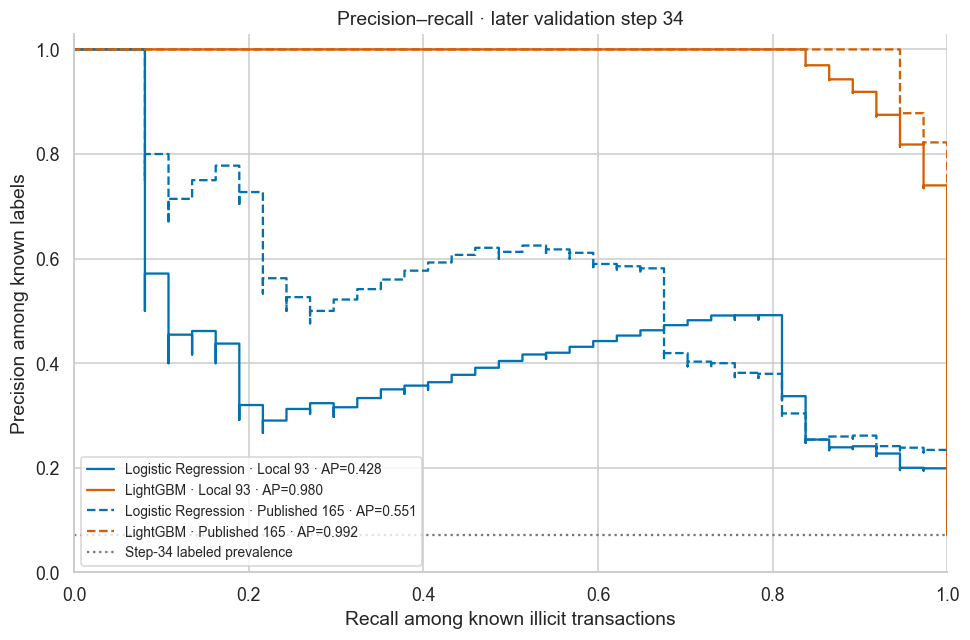

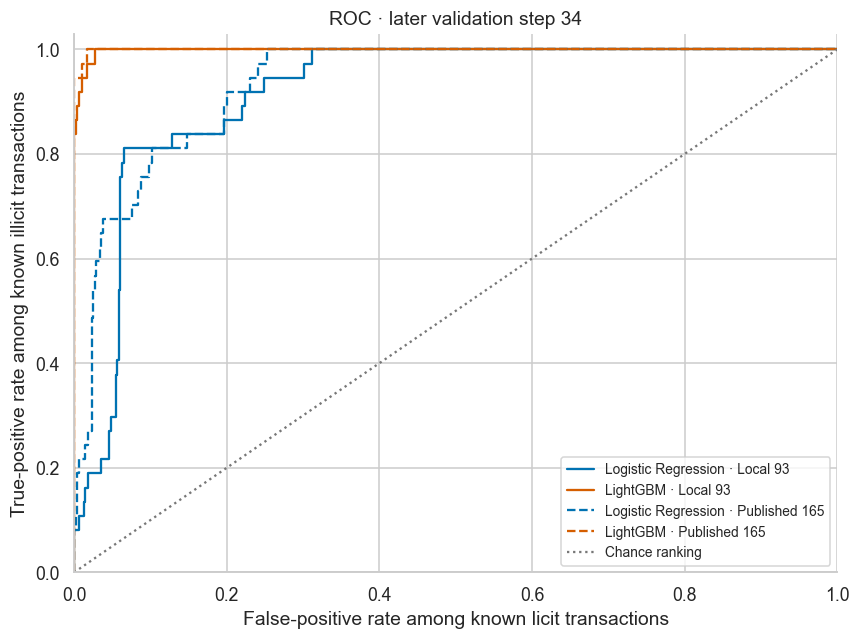

In [6]:
headline_lookup = selected_table.loc[selected_table.model_id.isin(headline_ids) & (selected_table.seed == PRIMARY_SEED)]

def selected_id(family, group_name):
    return headline_lookup.loc[(headline_lookup.family == family)
                               & (headline_lookup.feature_configuration == group_name), "model_id"].item()

def audit_frame(model_id, calibration="raw"):
    return audit_predictions.loc[audit_predictions.model_name == f"{model_id}__{calibration}"].copy()

fig, ax = plt.subplots(figsize=(9, 6))
for group_name, linestyle in [("local93", "-"), ("published165", "--")]:
    for family in FAMILY_NAMES:
        frame = audit_frame(selected_id(family, group_name))
        precision, recall, _ = precision_recall_curve(frame.true_label, frame.predicted_probability)
        ap = average_precision_score(frame.true_label, frame.predicted_probability)
        ax.step(recall, precision, where="post", color=COLORS[family], linestyle=linestyle,
                label=f"{FAMILY_NAMES[family]} · {GROUP_NAMES[group_name]} · AP={ap:.3f}")
ax.axhline(audit_rows.target.mean(), color="#777777", linestyle=":", label="Step-34 labeled prevalence")
ax.set(title="Precision–recall · later validation step 34", xlabel="Recall among known illicit transactions", ylabel="Precision among known labels", xlim=(0, 1), ylim=(0, 1.03))
ax.legend(fontsize=9, loc="lower left")
save_figure(fig, "stage2_01_precision_recall")

fig, ax = plt.subplots(figsize=(8, 6))
for group_name, linestyle in [("local93", "-"), ("published165", "--")]:
    for family in FAMILY_NAMES:
        frame = audit_frame(selected_id(family, group_name))
        fpr, tpr, _ = roc_curve(frame.true_label, frame.predicted_probability)
        ax.plot(fpr, tpr, color=COLORS[family], linestyle=linestyle,
                label=f"{FAMILY_NAMES[family]} · {GROUP_NAMES[group_name]}")
ax.plot([0, 1], [0, 1], color="#777777", linestyle=":", label="Chance ranking")
ax.set(title="ROC · later validation step 34", xlabel="False-positive rate among known licit transactions", ylabel="True-positive rate among known illicit transactions", xlim=(0, 1), ylim=(0, 1.03))
ax.legend(fontsize=9, loc="lower right")
save_figure(fig, "stage2_02_roc")

**Interpretation:** ROC-AUC can look strong while review precision or minority recall remains poor. AP is the primary ranking metric, but is prevalence-dependent and may vary across snapshots. These curves describe one later validation period; no final-test superiority or statistical significance is established.

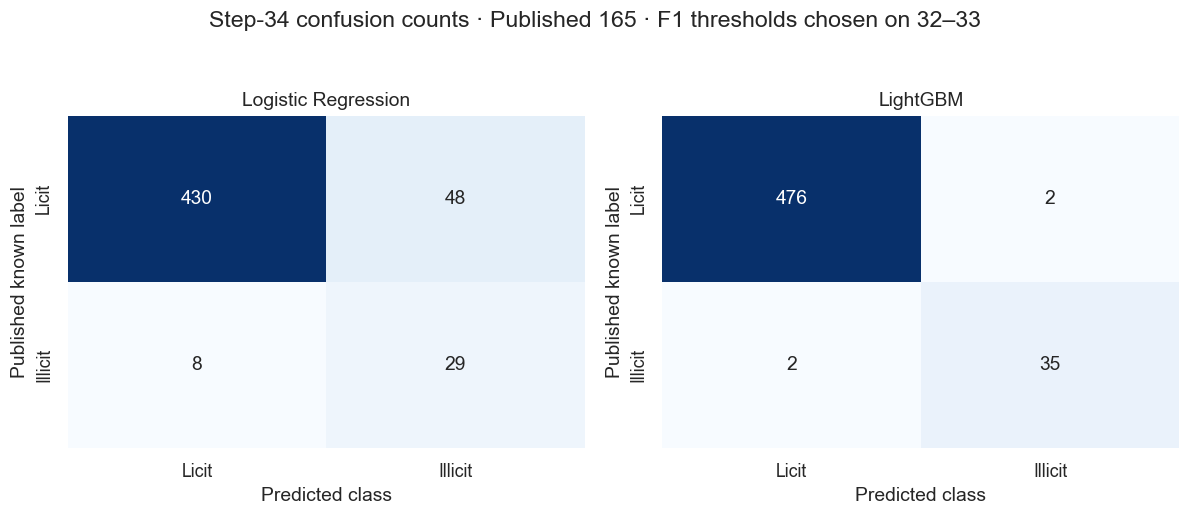

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, family in zip(axes, FAMILY_NAMES):
    model_id = selected_id(family, "published165")
    frame = audit_frame(model_id)
    rule = selected_models[model_id]["raw_thresholds"]
    metrics = binary_metrics(frame.true_label, frame.predicted_probability, rule["f1_threshold"])
    matrix = np.array([[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Licit", "Illicit"], yticklabels=["Licit", "Illicit"])
    ax.set(title=FAMILY_NAMES[family], xlabel="Predicted class", ylabel="Published known label")
fig.suptitle("Step-34 confusion counts · Published 165 · F1 thresholds chosen on 32–33", y=1.04)
save_figure(fig, "stage2_03_confusion_matrices")

**Interpretation:** The thresholds were chosen for calibration-window F1, not zero false alarms or maximal step-34 recall. Confusion counts make the small positive population and threshold trade-off visible. The all-feature models share precomputed graph-derived inputs.

## 7. LightGBM feature importance

Gain importance summarizes how training splits used features. It is not causal evidence, a significance test, or proof that a feature is available at prediction time. Correlated inputs can share or substitute for importance. Color identifies local versus published neighborhood groups.

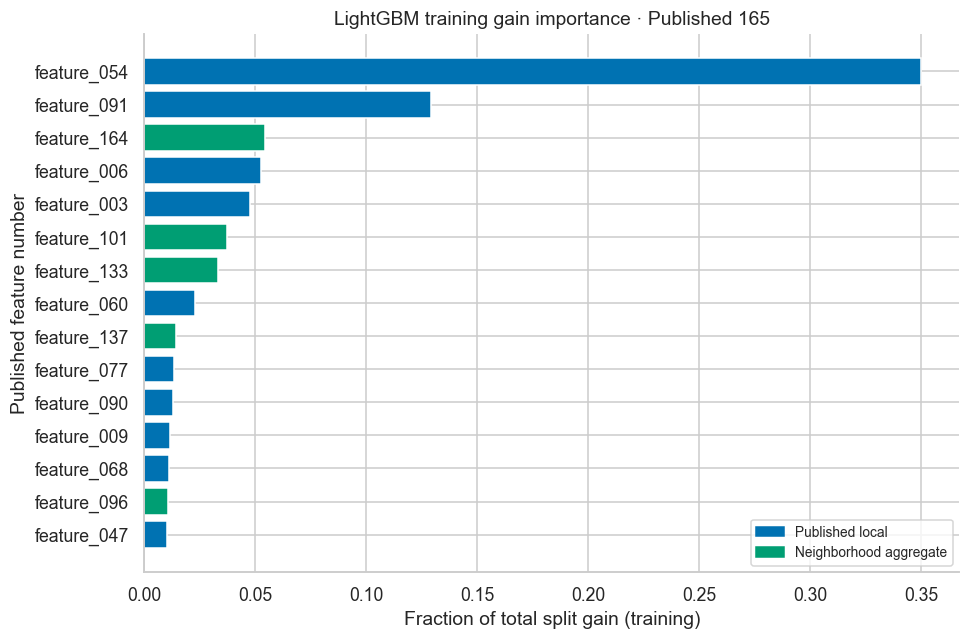

In [8]:
lightgbm_id = selected_id("lightgbm", "published165")
lightgbm_bundle = selected_models[lightgbm_id]
importance = pd.DataFrame({"feature": lightgbm_bundle["feature_columns"],
                           "gain": lightgbm_bundle["base_model"].feature_importances_})
importance["gain_fraction"] = importance.gain / importance.gain.sum()
importance["group"] = np.where(importance.feature.str[8:].astype(int) >= 95, "Neighborhood aggregate", "Published local")
importance.to_csv(RESULT_DIR / "lightgbm_gain_importance.csv", index=False)
top_importance = importance.nlargest(15, "gain_fraction").sort_values("gain_fraction")
fig, ax = plt.subplots(figsize=(9, 6))
importance_colors = {"Published local": "#0072B2", "Neighborhood aggregate": "#009E73"}
ax.barh(top_importance.feature, top_importance.gain_fraction,
        color=[importance_colors[group] for group in top_importance.group])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=color, label=name) for name, color in importance_colors.items()], fontsize=9)
ax.set(title="LightGBM training gain importance · Published 165", xlabel="Fraction of total split gain (training)", ylabel="Published feature number")
save_figure(fig, "stage2_04_feature_importance")

**Interpretation:** Importance attached to neighborhood features demonstrates that this tabular model can exploit engineered relational information. Removing those columns is a different information configuration; it does not prove that retained local features are leakage-free. These importances do not trigger any feature reselection in this notebook.

## 8. Imbalance and calibration assessment

Reliability curves use five quantile bins of the held-out step-34 scores; score histograms show where predictions are concentrated. Sparse positive counts and dependent observations prevent precise calibration claims. The Platt coefficients and fit-window sizes are saved for inspection. No test labels or step-34 labels fit the transform.

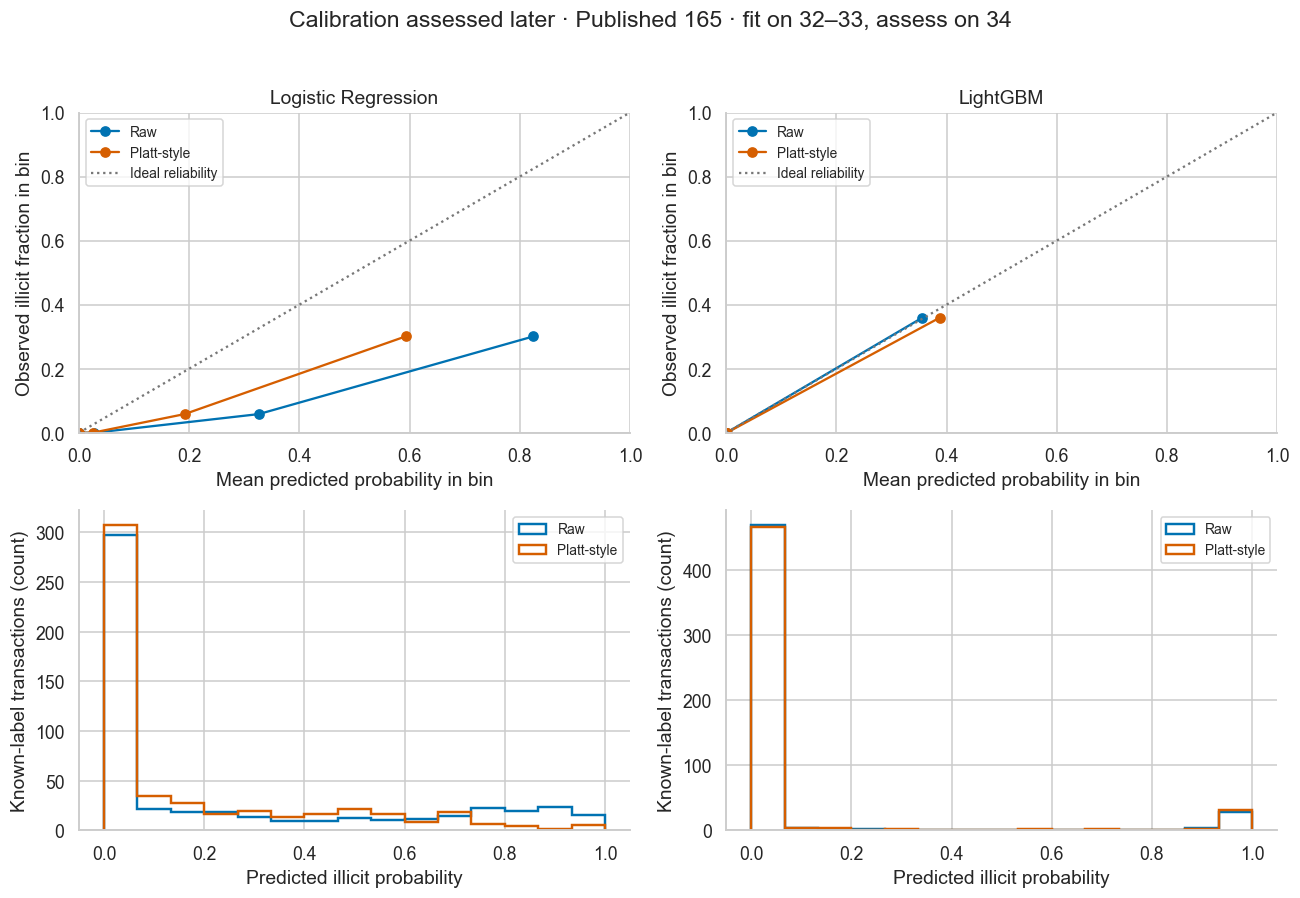

calibration                                             platt      raw  \
family              feature_configuration  weighting                     
lightgbm            conservative18         balanced   0.03813  0.06519   
                    local93                balanced   0.01165  0.01135   
                    published165           ordinary   0.00631  0.00509   
                    published165_plus_time ordinary   0.00616  0.00472   
logistic_regression conservative18         balanced   0.08257  0.37236   
                    local93                ordinary   0.07863  0.07197   
                    published165           ordinary   0.06649  0.11976   
                    published165_plus_time ordinary   0.06640  0.11976   

calibration                                           platt_minus_raw_brier  
family              feature_configuration  weighting                         
lightgbm            conservative18         balanced                -0.02706  
                    local93                balanced                 0.00030  
                    published165           ordinary                 0.00123  
                    published165_plus_time ordinary                 0.00144  
logistic_regression conservative18         balanced                -0.28979  
                    local93                ordinary                 0.00666  
                    published165           ordinary                -0.05327  
                    published165_plus_time ordinary                -0.05336

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, family in enumerate(FAMILY_NAMES):
    model_id = selected_id(family, "published165")
    for variant, color, label in [("raw", "#0072B2", "Raw"), ("platt", "#D55E00", "Platt-style")]:
        frame = audit_frame(model_id, variant)
        observed, predicted = calibration_curve(frame.true_label, frame.predicted_probability,
                                                n_bins=5, strategy="quantile")
        axes[0, column].plot(predicted, observed, marker="o", color=color, label=label)
        axes[1, column].hist(frame.predicted_probability, bins=np.linspace(0, 1, 16),
                             histtype="step", linewidth=1.6, color=color, label=label)
    axes[0, column].plot([0, 1], [0, 1], linestyle=":", color="#777777", label="Ideal reliability")
    axes[0, column].set(title=FAMILY_NAMES[family], xlabel="Mean predicted probability in bin", ylabel="Observed illicit fraction in bin", xlim=(0, 1), ylim=(0, 1))
    axes[1, column].set(xlabel="Predicted illicit probability", ylabel="Known-label transactions (count)")
    axes[0, column].legend(fontsize=9)
    axes[1, column].legend(fontsize=9)
fig.suptitle("Calibration assessed later · Published 165 · fit on 32–33, assess on 34", y=1.02)
save_figure(fig, "stage2_05_reliability")

calibration_comparison = headline_metrics.pivot_table(index=["family", "feature_configuration", "weighting"],
                                                      columns="calibration", values="brier_score")
calibration_comparison["platt_minus_raw_brier"] = calibration_comparison.platt - calibration_comparison.raw
display(calibration_comparison.round(5))
calibration_comparison.to_csv(RESULT_DIR / "calibration_comparison.csv")

**Interpretation:** Calibration learned from steps 32–33 may transfer poorly to the later snapshot, especially if its class prevalence changes. A positive Platt slope preserves native score order, but finite-precision probability saturation can create or resolve ties and change AP. We use native decision scores to avoid additional ties from arbitrary probability clipping. AP may otherwise stay unchanged while Brier score changes substantially. Both raw and calibrated results are retained; we do not choose a method retrospectively using step 34. Quantile bins can mix rare high scores with negatives and conceal tail errors; the score histograms and small labeled counts should be read with the curve.

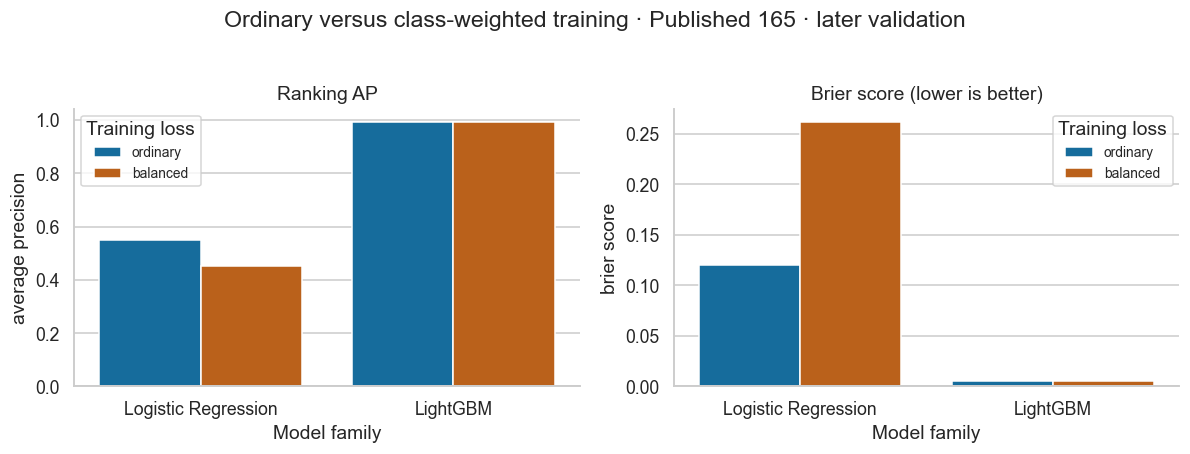

In [10]:
imbalance_rows = metrics_table.loc[(metrics_table.calibration == "raw")
                                  & (metrics_table.feature_configuration == "published165")
                                  & (metrics_table.seed == PRIMARY_SEED)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ["average_precision", "brier_score"], ["Ranking AP", "Brier score (lower is better)"]):
    sns.barplot(data=imbalance_rows, x="family", y=metric, hue="weighting", errorbar=None,
                palette={"ordinary": "#0072B2", "balanced": "#D55E00"}, ax=ax)
    ax.set(title=title, xlabel="Model family", ylabel=metric.replace("_", " "))
    ax.set_xticks(range(2), ["Logistic Regression", "LightGBM"])
    ax.legend(title="Training loss", fontsize=9)
fig.suptitle("Ordinary versus class-weighted training · Published 165 · later validation", y=1.03)
save_figure(fig, "stage2_06_class_weighting")

**Interpretation:** Weighting changes the learning objective and can trade probability accuracy for minority emphasis. Each regime received the same small search budget, but its selected parameters may differ; this is a practical comparison, not an isolated causal effect of the weights.

## 9. Threshold and labeled-review workload

Threshold curves below are diagnostic plots on step 34. Vertical rules were fixed earlier on steps 32–33 and are not moved after inspecting these curves. Review budgets rank candidates without an F1 threshold and count only transactions with known labels.

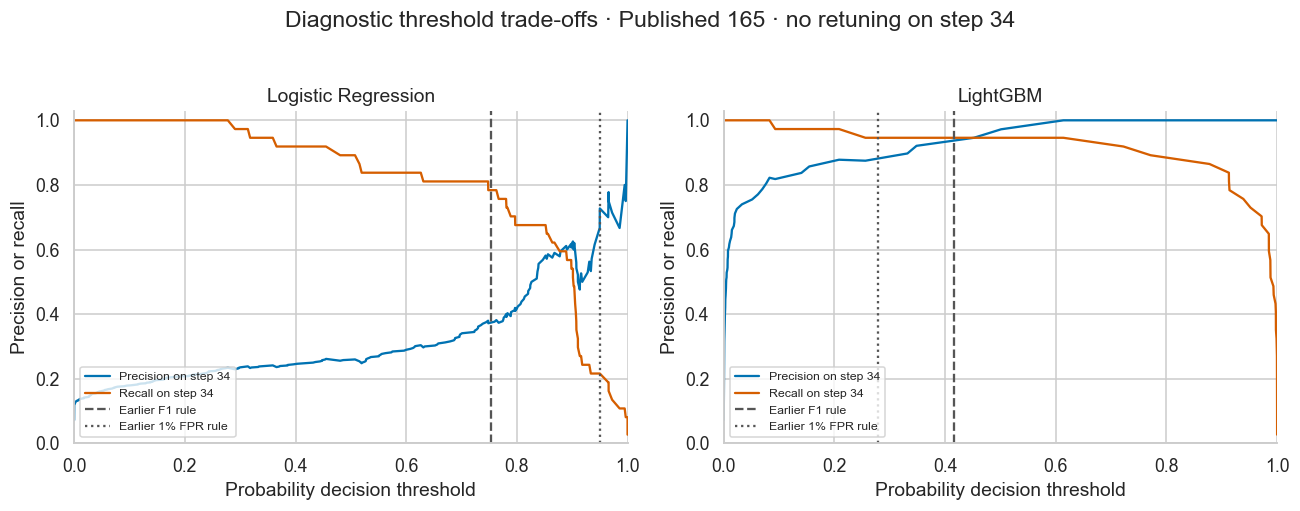

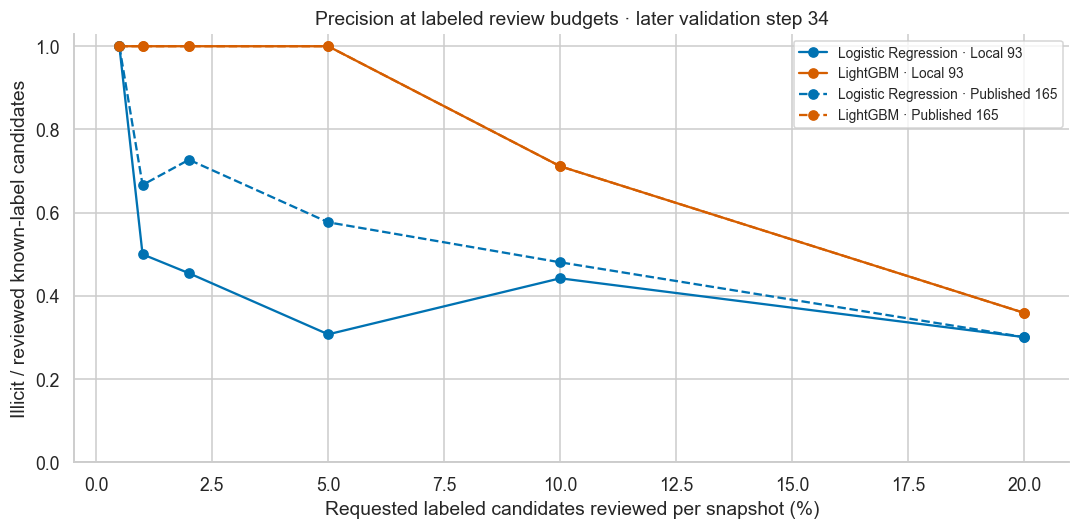

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, family in zip(axes, FAMILY_NAMES):
    model_id = selected_id(family, "published165")
    frame = audit_frame(model_id)
    precision, recall, thresholds = precision_recall_curve(frame.true_label, frame.predicted_probability)
    ax.plot(thresholds, precision[:-1], color="#0072B2", label="Precision on step 34")
    ax.plot(thresholds, recall[:-1], color="#D55E00", label="Recall on step 34")
    for key, style, label in [("f1_threshold", "--", "Earlier F1 rule"), ("fpr_threshold", ":", "Earlier 1% FPR rule")]:
        threshold = selected_models[model_id]["raw_thresholds"][key]
        if np.isfinite(threshold):
            ax.axvline(threshold, color="#555555", linestyle=style, label=label)
    ax.set(title=FAMILY_NAMES[family], xlabel="Probability decision threshold", ylabel="Precision or recall", xlim=(0, 1), ylim=(0, 1.03))
    ax.legend(fontsize=8, loc="lower left")
fig.suptitle("Diagnostic threshold trade-offs · Published 165 · no retuning on step 34", y=1.03)
save_figure(fig, "stage2_07_threshold_tradeoffs")

budget_records = []
for model_id in headline_lookup.model_id:
    bundle = selected_models[model_id]
    frame = audit_frame(model_id)
    for fraction in REVIEW_FRACTIONS:
        budget_records.append({"model_id": model_id, "family": bundle["family"],
            "feature_configuration": bundle["feature_configuration"], "budget_fraction": fraction,
            **review_budget_metrics(frame, fraction=fraction)})
budget_table = pd.DataFrame(budget_records)
budget_table.to_csv(RESULT_DIR / "labeled_review_budgets.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 5))
for group_name, linestyle in [("local93", "-"), ("published165", "--")]:
    for family in FAMILY_NAMES:
        view = budget_table.loc[(budget_table.family == family) & (budget_table.feature_configuration == group_name)]
        ax.plot(100 * view.budget_fraction, view.review_precision, marker="o", color=COLORS[family],
                linestyle=linestyle, label=f"{FAMILY_NAMES[family]} · {GROUP_NAMES[group_name]}")
ax.set(title="Precision at labeled review budgets · later validation step 34", xlabel="Requested labeled candidates reviewed per snapshot (%)", ylabel="Illicit / reviewed known-label candidates", ylim=(0, 1.03))
ax.legend(fontsize=9)
save_figure(fig, "stage2_08_review_budgets")

**Interpretation:** At very small fractions, the budget contains only a few transactions and one changed label can substantially alter precision. Ceiling-rounded counts are saved with the table. These results do not identify precision among unlabeled operational candidates or the actual cost of investigations.

## 10. Feature configurations and temporal sensitivity

Compare the same configurations across model families. Plots distinguish selection-window reuse from later validation assessment. Time is an explicit extra input, not an inferred improvement or a default chosen using step 34. Trees cannot generally extrapolate a time split beyond the training time range; linear time effects also impose a strong extrapolation assumption.

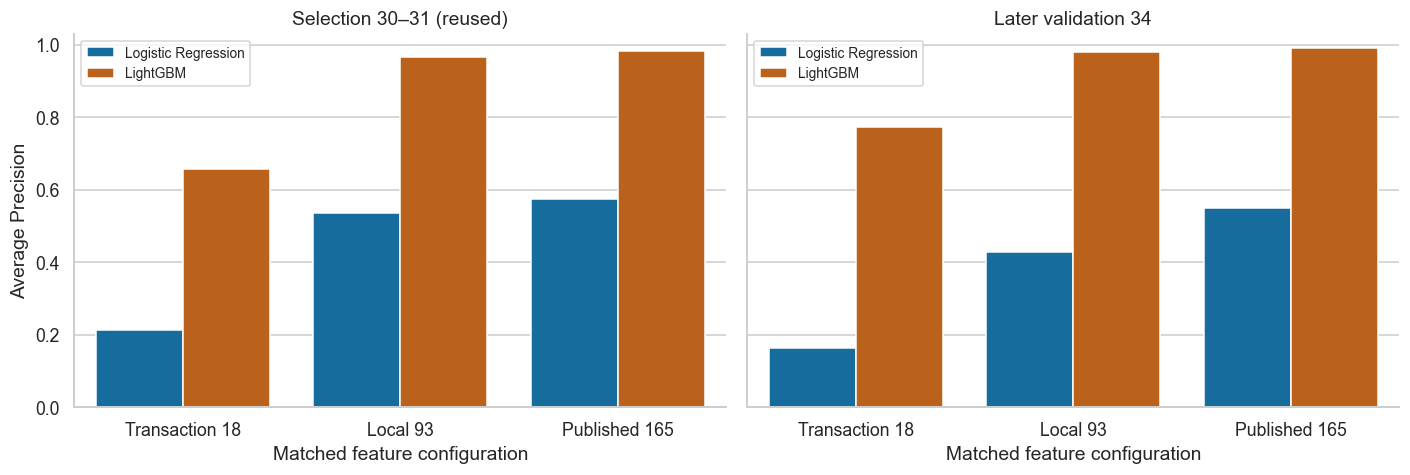

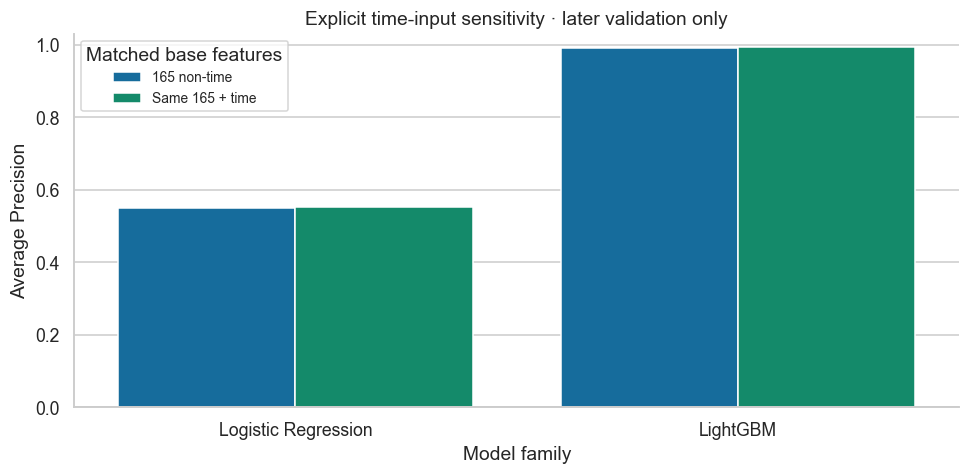

In [12]:
comparison_records = []
for row in headline_lookup.itertuples():
    for role, role_rows in [("Selection 30–31 (reused)", selection_rows), ("Later validation 34", audit_rows)]:
        frame = raw_predictions.loc[(raw_predictions.model_name == row.model_id + "__raw")
                                    & raw_predictions.time_step.isin(role_rows.time_step.unique())]
        comparison_records.append({"family": FAMILY_NAMES[row.family], "feature_configuration": row.feature_configuration,
            "role": role, "average_precision": average_precision_score(frame.true_label, frame.predicted_probability)})
feature_comparison = pd.DataFrame(comparison_records)
feature_comparison.to_csv(RESULT_DIR / "feature_group_comparison.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, role in zip(axes, ["Selection 30–31 (reused)", "Later validation 34"]):
    sns.barplot(data=feature_comparison.loc[(feature_comparison.role == role)
                    & (feature_comparison.feature_configuration != "published165_plus_time")],
                x="feature_configuration", y="average_precision", hue="family", errorbar=None,
                order=["conservative18", "local93", "published165"],
                palette={"Logistic Regression": COLORS["logistic_regression"], "LightGBM": COLORS["lightgbm"]}, ax=ax)
    ax.set(title=role, xlabel="Matched feature configuration", ylabel="Average Precision", ylim=(0, 1.03))
    ax.set_xticks(range(3), ["Transaction 18", "Local 93", "Published 165"])
    ax.legend(fontsize=9, title=None)
save_figure(fig, "stage2_09_feature_groups")

fig, ax = plt.subplots(figsize=(9, 4.5))
time_view = feature_comparison.loc[(feature_comparison.role == "Later validation 34")
    & feature_comparison.feature_configuration.isin(["published165", "published165_plus_time"])]
sns.barplot(data=time_view, x="family", y="average_precision", hue="feature_configuration", errorbar=None,
            palette={"published165": "#0072B2", "published165_plus_time": "#009E73"}, ax=ax)
ax.set(title="Explicit time-input sensitivity · later validation only", xlabel="Model family", ylabel="Average Precision", ylim=(0, 1.03))
ax.legend(title="Matched base features", labels=["165 non-time", "Same 165 + time"], fontsize=9)
save_figure(fig, "stage2_10_time_sensitivity")

**Interpretation:** A difference between 18, 93 and 165 inputs combines information scope and source-provenance effects; it is not proof of leakage magnitude or graph learning's value. Within the 165-versus-166 sensitivity the added column is time, but small-grid selection can still change the selected loss or parameters. No final-test result is available.

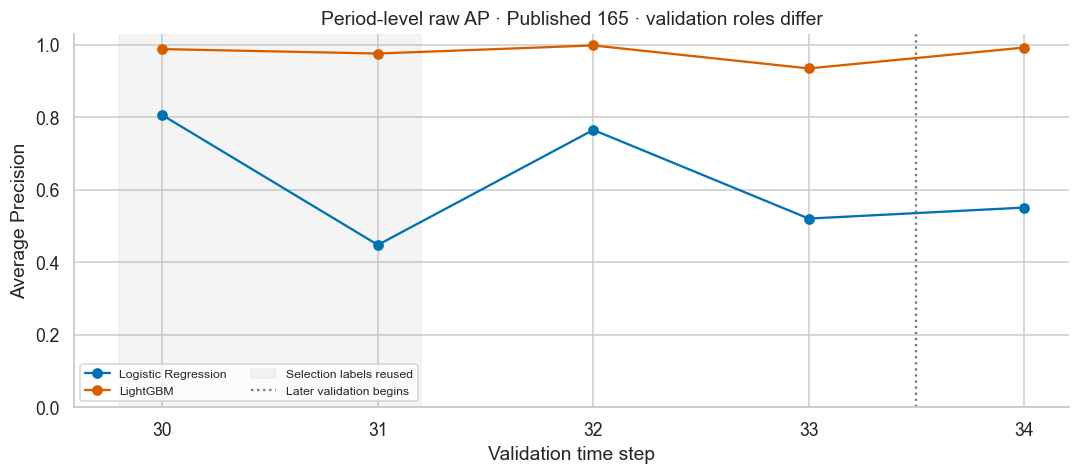

,family,time_step,average_precision,illicit,known_labels
0,Logistic Regression,30,0.805454,83,524
1,Logistic Regression,31,0.447861,106,710
2,Logistic Regression,32,0.764857,342,1323
3,Logistic Regression,33,0.520460,23,441
4,Logistic Regression,34,0.550783,37,515
5,LightGBM,30,0.987679,83,524
6,LightGBM,31,0.975472,106,710
7,LightGBM,32,0.997755,342,1323
8,LightGBM,33,0.934358,23,441
9,LightGBM,34,0.991899,37,515


In [13]:
period_records = []
for family in FAMILY_NAMES:
    model_id = selected_id(family, "published165")
    view = raw_predictions.loc[raw_predictions.model_name == model_id + "__raw"]
    for step, frame in view.groupby("time_step", sort=True):
        period_records.append({"family": FAMILY_NAMES[family], "time_step": int(step),
            "average_precision": binary_metrics(frame.true_label, frame.predicted_probability)["average_precision"],
            "illicit": int(frame.true_label.sum()), "known_labels": len(frame)})
period_table = pd.DataFrame(period_records)
period_table.to_csv(RESULT_DIR / "validation_period_metrics.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
for family in FAMILY_NAMES:
    view = period_table.loc[period_table.family == FAMILY_NAMES[family]]
    ax.plot(view.time_step, view.average_precision, marker="o", color=COLORS[family], label=FAMILY_NAMES[family])
ax.axvspan(29.8, 31.2, color="#aaaaaa", alpha=0.12, label="Selection labels reused")
ax.axvline(33.5, color="#777777", linestyle=":", label="Later validation begins")
ax.set(title="Period-level raw AP · Published 165 · validation roles differ", xlabel="Validation time step", ylabel="Average Precision", xticks=[30, 31, 32, 33, 34], ylim=(0, 1.03))
ax.legend(fontsize=8, ncol=2)
save_figure(fig, "stage2_11_validation_periods")
display(period_table)

**Interpretation:** Period AP reflects both ranking and the period's selected label distribution. Early values share selection labels and are not independent assessments. With only one untouched later validation snapshot, formal regime-level robustness, uncertainty intervals and final conclusions must wait for subsequent stages.

## 11. Save configurations, verify artifacts and record findings

All per-transaction predictions and fitted model bundles remain in Git-ignored local directories. The seven-column prediction schema is shared with later notebooks; feature group, weighting and calibration are encoded in `model_name` and saved in the model catalog. Aggregate tables and figures contain no transaction IDs. Artifacts are verified after reloading, but only load trusted local model files.

The Stage 2 development record freezes the candidates, split roles, selected models, transformations and operating rules produced here. This historical development record precedes the final methodology freeze and test evaluation.

In [14]:
selected_configuration_records = []
for model_id, bundle in selected_models.items():
    rules = {}
    for rule_name in ["raw_thresholds", "calibrated_thresholds"]:
        rule = dict(bundle[rule_name])
        # JSON null means an all-negative rule; the fitted bundle retains +infinity.
        if not np.isfinite(rule["fpr_threshold"]):
            rule["fpr_threshold"] = None
        rules[rule_name] = rule
    selected_configuration_records.append({"model_id": model_id,
        "family": bundle["family"], "feature_configuration": bundle["feature_configuration"],
        "feature_columns": bundle["feature_columns"], "weighting": bundle["weighting"],
        "seed": bundle["seed"], "selected_parameters": bundle["selected_parameters"],
        "estimator_parameters": (bundle["base_model"].named_steps["classifier"].get_params(deep=False)
                                 if bundle["family"] == "logistic_regression"
                                 else bundle["base_model"].get_params(deep=False)),
        "preprocessing": (bundle["base_model"].named_steps["scale"].get_params(deep=False)
                          if bundle["family"] == "logistic_regression" else "none"),
        "headline_selected_on_30_31": model_id in headline_ids, **rules})

versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "matplotlib", "seaborn", "joblib", "threadpoolctl"]}
run_config = {
    "stage": 2, "run_mode": RUN_MODE, "exploratory": QUICK_RUN, "seeds": SEEDS,
    "python": platform.python_version(), "architecture": platform.machine(), "device": "cpu",
    "versions": versions, "native_dependency": "Homebrew libomp; installation instructions in README",
    "raw_sha256": raw_hashes, "training_steps": [1, 29], "validation_roles": VALIDATION_ROLES,
    "feature_sets": FEATURE_SETS, "parameter_grid": PARAMETER_GRID, "weighting_regimes": WEIGHTING_REGIMES,
    "selected_models": selected_configuration_records, "target_fpr": TARGET_FPR, "review_k_per_snapshot": REVIEW_K,
    "review_fractions": REVIEW_FRACTIONS, "n_jobs": N_JOBS,
    "calibration": {"method": "unweighted logistic on native decision scores", "C": 1000.0,
                    "min_per_class": 20, "fit_steps": [32, 33], "assessment_steps": [34]},
    "infinite_fpr_threshold_json_representation": "null means predict none",
    "prediction_columns": PREDICTION_COLUMNS, "predictions_max_step": 34,
    "base_model_artifacts": len(selected_models), "candidate_fits": len(search_table),
    "raw_prediction_rows": len(raw_predictions), "calibrated_prediction_rows": len(calibrated_predictions),
    "population_checks_passed": True, "artifact_roundtrip_checks_passed": len(artifact_checks),
    "feature_provenance": "none of the configurations is certified leakage-free",
    "final_test_predictions_computed": False, "final_test_rankings_computed": False,
    "seconds": round(time.perf_counter() - started_at, 3), "figures": figure_names,
}
(RESULT_DIR / "selected_configurations.json").write_text(json.dumps(run_config, indent=2, allow_nan=False) + "\n")
# Constant-score reference: training prevalence for Brier; AP equals displayed prevalence.
prior = float(train_rows.target.mean())
prior_metrics = binary_metrics(audit_rows.target.to_numpy(dtype=int), np.full(len(audit_rows), prior))
pd.DataFrame([{"reference": "constant training prevalence", **prior_metrics}]).to_csv(RESULT_DIR / "prior_reference.csv", index=False)

main_view = headline_metrics.loc[(headline_metrics.feature_configuration == "published165")
                                 & (headline_metrics.calibration == "raw")]
summary_lines = [
    f"- Trained **{len(search_table)} candidates** on {len(train_rows):,} known training labels; selected **{len(selected_models)} base-model bundles**.",
    f"- Selected candidates/weighting on steps 30–31; calibrated and chose operating rules on 32–33; assessed on **{len(audit_rows)} step-34 labels ({int(audit_rows.target.sum())} illicit)**.",
    f"- Saved **{len(raw_predictions):,} raw validation predictions**, **{len(calibrated_predictions):,} calibrated later-validation predictions**, configs, timings and artifacts locally.",
    f"- Verified common evaluation identities/labels and exact prediction roundtrips for all **{len(artifact_checks)}** model bundles.",
    f"- Generated **{len(figure_names)}** notebook figures. No final-test probabilities or rankings were computed.",
]
for row in main_view.itertuples():
    summary_lines.append(f"- {FAMILY_NAMES[row.family]} with Published 165 and {row.weighting} training: later-validation raw **AP {row.average_precision:.4f}**, **Brier {row.brier_score:.4f}**.")
summary_lines.append("- Calibration transfer, small late validation, selected labels and published-feature leakage limit interpretation. These are not final test findings.")
if QUICK_RUN:
    summary_lines.insert(0, "**QUICK_RUN — exploratory only.**")
display(Markdown("\n".join(summary_lines)))
print(f"Stage 2 runtime: {run_config['seconds']:.1f} seconds.")

- Trained **32 candidates** on 26,381 known training labels; selected **16 base-model bundles**.
- Selected candidates/weighting on steps 30–31; calibrated and chose operating rules on 32–33; assessed on **515 step-34 labels (37 illicit)**.
- Saved **56,208 raw validation predictions**, **8,240 calibrated later-validation predictions**, configs, timings and artifacts locally.
- Verified common evaluation identities/labels and exact prediction roundtrips for all **16** model bundles.
- Generated **11** notebook figures. No final-test probabilities or rankings were computed.
- Logistic Regression with Published 165 and ordinary training: later-validation raw **AP 0.5508**, **Brier 0.1198**.
- LightGBM with Published 165 and ordinary training: later-validation raw **AP 0.9919**, **Brier 0.0051**.
- Calibration transfer, small late validation, selected labels and published-feature leakage limit interpretation. These are not final test findings.

Stage 2 runtime: 48.6 seconds.


## References and methodological notes

- [Stage 1 leakage audit](../reports/leakage_audit.md) and [research protocol](../reports/research_protocol.md); [Šafář et al. (2026)](https://doi.org/10.1016/j.fsidi.2026.302124).
- [scikit-learn 1.7 probability calibration](https://scikit-learn.org/1.7/modules/calibration.html): reliability assessment and the distinction between calibration and Brier loss.
- [scikit-learn Average Precision](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.average_precision_score.html): AP is non-interpolated rather than trapezoidal PR area.
- [LightGBM 4.6 classifier documentation](https://lightgbm.readthedocs.io/en/v4.6.0/pythonapi/lightgbm.LGBMClassifier.html): class weighting and probability estimates; [deterministic CPU parameters](https://lightgbm.readthedocs.io/en/v4.6.0/Parameters.html).

No uncertainty intervals or statistical superiority claims are made from this single late validation snapshot. No random splitting, validation-fitted classifier scaler, test-label calibration, or unknown-as-negative evaluation is used.